# Model choice, cut-off and what the model is worth

At the 2024-03-01 train date:
1. Which candidate should be deployed, judged on train, validation, test and out-of-time AUC together, and how sure is that choice?
2. The score is a probability of default; a lending decision needs a cut-off on it. On the test split, does the score read as a probability, and what does each cut-off catch and cost?
3. What is the model worth in loans and dollars, read from the loan ledger at typical lending rates, and where does the cost of errors put the cut-off?
4. What does a fixed cut-off do once applicants have no clickstream?
5. What drives the score?

In [1]:
import json
import pickle
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, precision_recall_curve

sys.path.insert(0, "..")  # the pipeline's scripts: the same data loading the model used
from model_train import load_training_data, split_train_test

pd.set_option("display.width", 200)

with open("../model_bank/model_selection_2024_03_01.json") as file:
    selection = json.load(file)
artefacts = {}
for version in selection["candidates"]:
    with open("../model_bank/" + version + ".pkl", "rb") as file:
        artefacts[version] = pickle.load(file)
for version, artefact in artefacts.items():
    print(version, artefact["hp_params"])
print("selected:", selection["selected_model"], "| on:", selection["selection_metric"], "| approved by:", selection["approved_by"])

credit_model_logreg_2024_03_01 {'C': 0.02069138081114789}
credit_model_xgb_2024_03_01 {'subsample': 0.6, 'n_estimators': 100, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
selected: credit_model_xgb_2024_03_01 | on: auc_test | approved by: None


## 1. Train, validation, test and out-of-time, side by side

In [2]:
aucs = pd.DataFrame(selection["metrics"]).T
aucs.index = [version.split("_")[2] for version in aucs.index]  # credit_model_xgb_2024_03_01 -> xgb
aucs.loc["xgb - logreg"] = aucs.loc["xgb"] - aucs.loc["logreg"]
aucs.round(4)

,auc_train,auc_cv,auc_test,auc_oot,train_test_gap
logreg,0.8382,0.8164,0.8115,0.8410,0.0267
xgb,0.8947,0.8316,0.8224,0.8558,0.0723
xgb - logreg,0.0565,0.0151,0.0110,0.0149,0.0455


In [3]:
# the test and out-of-time applications exactly as model_train.py built them (same function, windows, sort, seed and
# stratification), scored by both candidates; the AUCs must equal the stored ones
config, train_test_pdf, oot_pdf = load_training_data(selection["train_date"], root="..")
train_pdf, test_pdf = split_train_test(train_test_pdf, config)
scores = {}
for version, artefact in artefacts.items():
    columns, p = artefact["feature_columns"], artefact["preprocessing_transformers"]
    scores[version] = {name: artefact["model"].predict_proba(p["stdscaler"].transform(p["imputer"].transform(pdf[columns])))[:, 1]
                       for name, pdf in [("test", test_pdf), ("oot", oot_pdf)]}
    print(version, "| AUC on the rebuilt test split:", roc_auc_score(test_pdf["label"], scores[version]["test"]),
          "| in the artefact:", artefact["results"]["auc_test"])
for name, pdf in [("train", train_pdf), ("test", test_pdf), ("out-of-time", oot_pdf)]:
    print(f"{name}: {len(pdf)} applications | {int(pdf['label'].sum())} defaulters | bad rate {pdf['label'].mean():.3f}")

# how sure is the choice? the AUC margin on 2,000 bootstrap resamples of the test and of the out-of-time applications
xgb_version, logreg_version = selection["selected_model"], [v for v in artefacts if v != selection["selected_model"]][0]
rng = np.random.default_rng(0)
for name, pdf in [("test", test_pdf), ("oot", oot_pdf)]:
    y = pdf["label"].to_numpy()
    margins = []
    for _ in range(2000):
        idx = rng.integers(0, len(y), len(y))
        margins.append(roc_auc_score(y[idx], scores[xgb_version][name][idx]) - roc_auc_score(y[idx], scores[logreg_version][name][idx]))
    margins = np.array(margins)
    print(f"{name}: xgb − logreg AUC = {margins.mean():+.4f}, 95% interval [{np.percentile(margins, 2.5):+.4f}, {np.percentile(margins, 97.5):+.4f}], "
          f"xgb ahead in {np.mean(margins > 0):.0%} of resamples")

credit_model_logreg_2024_03_01 | AUC on the rebuilt test split: 0.8114605225603901 | in the artefact: 0.8114605225603901
credit_model_xgb_2024_03_01 | AUC on the rebuilt test split: 0.8224488207363586 | in the artefact: 0.8224488207363586
train: 2468 applications | 695 defaulters | bad rate 0.282
test: 617 applications | 174 defaulters | bad rate 0.282
out-of-time: 952 applications | 279 defaulters | bad rate 0.293


test: xgb − logreg AUC = +0.0111, 95% interval [-0.0090, +0.0315], xgb ahead in 86% of resamples


oot: xgb − logreg AUC = +0.0151, 95% interval [+0.0008, +0.0298], xgb ahead in 98% of resamples


**Findings:**
- The splits are the ones `model_train.py` built: 2,468 training, 617 test and 952 out-of-time applications. The split is stratified by the label, so train and test share a bad rate of 0.282; the out-of-time months, later applications, default a little more often (0.293).
- XGBoost leads on all three sets it was not fitted on: validation by 0.015, test by 0.011 and the out-of-time months by 0.015. Each margin is small: on its own the test margin is within sampling noise (95% interval about −0.009 to +0.032, XGBoost ahead in 86% of resamples), and the out-of-time margin just clears it (+0.001 to +0.030, 98%). The case for XGBoost is that all three agree.
- XGBoost's train AUC is 0.072 above its test AUC, against 0.027 for logistic regression: it fits its training applications noticeably better than new ones, so its training score overstates it. Its trees are shallow (depth 2, 100 trees), and on new applications it is still the better model. The gap means "expect less than the training score", not "worse than logistic regression".
- Decision: deploy XGBoost, and keep logistic regression in the model bank as the stable alternative. At the next refresh the approver compares the gaps again: if XGBoost's lead on test disappears while its gap stays this large, logistic regression is the safer choice.

## 2. Precision and recall at each cut-off, on the test split

AUC measures how well the scores rank applicants. A lending decision needs a cut-off: applications scoring at or above it are declined or referred. **Precision** is the share of flagged applicants who default; **recall** is the share of defaulters who are flagged.

logreg | best precision at recall 0.5 or more: 0.702 | at recall 0.8 or more: 0.478
xgb | best precision at recall 0.5 or more: 0.773 | at recall 0.8 or more: 0.502


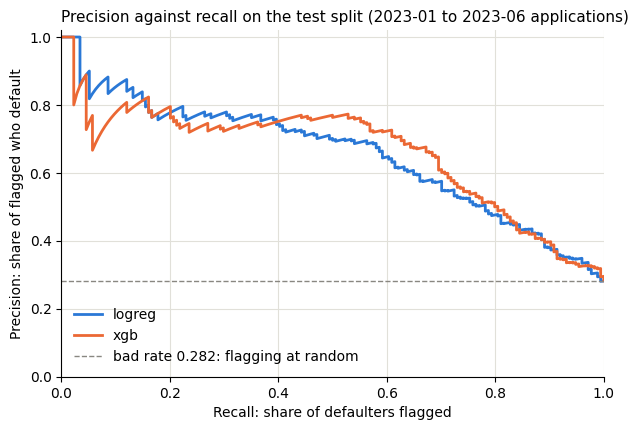

In [4]:
y_test = test_pdf["label"]
test_scores = {version: s["test"] for version, s in scores.items()}
fig, ax = plt.subplots(figsize=(7, 4.5))
for (version, s), colour in zip(test_scores.items(), ["#2a78d6", "#eb6834"]):
    precision, recall, _ = precision_recall_curve(y_test, s)
    ax.plot(recall, precision, color=colour, linewidth=2, label=version.split("_")[2])
    print(version.split("_")[2], "| best precision at recall 0.5 or more:", round(precision[recall >= 0.5].max(), 3),
          "| at recall 0.8 or more:", round(precision[recall >= 0.8].max(), 3))
ax.axhline(y_test.mean(), color="#898781", linewidth=1, linestyle="--", label=f"bad rate {y_test.mean():.3f}: flagging at random")
ax.set_xlabel("Recall: share of defaulters flagged")
ax.set_ylabel("Precision: share of flagged who default")
ax.set_title("Precision against recall on the test split (2023-01 to 2023-06 applications)", loc="left", fontsize=11)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.legend(frameon=False, loc="lower left")
plt.show()

In [5]:
# the selected model: cut-offs that flag the riskiest 10% to 50% of applications, and 0.5, the cut-off predict() uses
selected = test_scores[selection["selected_model"]]
y = y_test.to_numpy()
rows = []
for cutoff in [np.quantile(selected, 1 - share) for share in [0.1, 0.2, 0.3, 0.4, 0.5]] + [0.5]:
    flagged = selected >= cutoff
    rows.append({
        "cut-off": cutoff,
        "share flagged": flagged.mean(),
        "precision": y[flagged].mean(),
        "recall": flagged[y == 1].mean(),
        "defaulters missed": int((~flagged & (y == 1)).sum()),
        "good customers flagged": int((flagged & (y == 0)).sum()),
    })
pd.DataFrame(rows).round(3)

,cut-off,share flagged,precision,recall,defaulters missed,good customers flagged
0,0.648,0.100,0.742,0.264,128,16
1,0.492,0.201,0.758,0.540,80,30
2,0.337,0.300,0.649,0.690,54,65
3,0.248,0.400,0.538,0.764,41,114
4,0.185,0.501,0.466,0.828,30,165
5,0.500,0.194,0.767,0.529,82,28


In [6]:
# does the score read as a probability? its mean against the bad rate on the test split, overall and in each tenth by score
tenth = pd.qcut(selected, 10, labels=range(1, 11))  # 1 = the tenth with the lowest scores, 10 = the riskiest
calibration = pd.DataFrame({"mean score": selected, "bad rate": y}).groupby(tenth, observed=True).mean()
calibration["gap"] = calibration["mean score"] - calibration["bad rate"]
print(f"mean score {selected.mean():.3f} | bad rate {y.mean():.3f} | largest gap in a tenth: {calibration['gap'].abs().max():.3f}")
calibration.round(3)

mean score 0.273 | bad rate 0.282 | largest gap in a tenth: 0.207


,mean score,bad rate,gap
1,0.040,0.016,0.024
2,0.069,0.129,-0.060
3,0.093,0.098,-0.005
4,0.128,0.113,0.015
5,0.164,0.129,0.035
6,0.217,0.180,0.036
7,0.293,0.210,0.084
8,0.395,0.426,-0.032
9,0.568,0.774,-0.207
10,0.765,0.742,0.023


**Findings:**
- The ranking is strong at the top: flagging the riskiest 10% or 20% of test applicants gives a precision of about 0.75 (three in four flagged applicants default), against a bad rate of 0.282.
- Catching more defaulters costs more good customers: the riskiest 20% hold 54% of the defaulters; catching 83% means flagging half the applicants, when fewer than half of those flagged default (precision 0.466).
- At 0.5 the model flags 19% of test applicants; 77% of them default, and it catches 53% of the defaulters.
- The two curves cross. For the riskiest few percent (recall below about 0.2) logistic regression is often the more precise; from a recall of about 0.4 to 0.75 XGBoost is. At a recall of 0.5 or more, XGBoost's best precision is 0.773 against 0.702.
- The score reads as a probability on average: its mean on test is 0.273 against a bad rate of 0.282. Not in every tenth by score: in the second-riskiest tenth (scores of about 0.5 to 0.65) 77% default against 57% predicted, so the riskiest fifth's expected loss read from the score is about 9 points short. With about 62 applications in a tenth, its bad rate is uncertain by about ±10 points from sampling alone, so that is the only tenth clearly off. In the safer half, where section 3's cut-offs fall (0.07 to 0.18), the score is within 6 points of the bad rate, so the cut-off rule, which reads the score as a probability, holds where it is used.
- Which cut-off is right depends on what a missed default costs against a good customer turned away: section 3 reads both from the ledger.

## 3. What the model is worth, from the loan ledger

The ledger (`lms_loan_daily.csv`) shows what every loan left unpaid after its last installment. Joined to the labels, it says what a default costs the bank; joined to the test split, it says what the model's ranking saves. The ledger records no interest, so the margin the bank earns on a loan that is repaid comes from typical lending rates: the one assumption below.

In [7]:
ledger = pd.read_csv("../data/lms_loan_daily.csv")
print("loans:", ledger["loan_id"].nunique(), "| loan amount:", ledger["loan_amt"].unique(), "| installments:", ledger["tenure"].unique(),
      "| installment due:", ledger.loc[ledger["installment_num"] > 0, "due_amt"].unique(), "(due × installments = loan amount: no interest in the ledger)")
final = ledger[ledger["installment_num"] == ledger["tenure"]][["loan_id", "Customer_ID", "loan_start_date", "balance"]].rename(columns={"balance": "unpaid"})
final["loan_start_date"] = pd.to_datetime(final["loan_start_date"])
final = final.merge(pd.read_parquet("../datamart/gold/label_store/")[["loan_id", "label"]], on="loan_id")
print(final.groupby("label")["unpaid"].describe().round(0).to_string())
print("defaulters who end fully repaid:", int((final.loc[final["label"] == 1, "unpaid"] == 0).sum()),
      "| non-defaulters with anything unpaid:", int((final.loc[final["label"] == 0, "unpaid"] > 0).sum()))
LOSS_PER_DEFAULT = final.loc[final["label"] == 1, "unpaid"].mean()
print(f"unpaid per defaulted loan: ${LOSS_PER_DEFAULT:,.0f} | unpaid per dollar lent, all loans: {final['unpaid'].sum() / (10000 * len(final)):.3f}")
months = final["loan_start_date"].dt.to_period("M").nunique()
APPLICATIONS_A_YEAR = len(final) / months * 12
print(f"ledger rows: {len(ledger):,} | unpaid ${final['unpaid'].sum():,.0f} on ${10000 * len(final):,.0f} lent, applications over {months} months")
print(f"applications a month: {len(final) / months:.0f} on average, so {APPLICATIONS_A_YEAR:,.0f} a year ({(final['loan_start_date'].dt.year == 2024).sum():,} in 2024) | "
      f"unpaid a year if everyone is approved: ${final['unpaid'].sum() / months * 12:,.0f}")

loans: 12500 | loan amount: [10000] | installments: [10] | installment due: [1000.] (due × installments = loan amount: no interest in the ledger)
        count    mean     std     min     25%     50%     75%      max
label                                                                 
0      8898.0     0.0     0.0     0.0     0.0     0.0     0.0      0.0
1      3602.0  7531.0  1071.0  6000.0  7000.0  7000.0  8000.0  10000.0
defaulters who end fully repaid: 0 | non-defaulters with anything unpaid: 0
unpaid per defaulted loan: $7,531 | unpaid per dollar lent, all loans: 0.217
ledger rows: 137,500 | unpaid $27,126,000 on $125,000,000 lent, applications over 25 months
applications a month: 500 on average, so 6,000 a year (6,016 in 2024) | unpaid a year if everyone is approved: $13,020,480


In [8]:
# the test split with each application's final unpaid balance and the selected model's score
test = test_pdf[["Customer_ID", "snapshot_date", "label"]].assign(score=selected, score_logreg=scores[logreg_version]["test"]).merge(
    final[["Customer_ID", "loan_start_date", "unpaid"]], left_on=["Customer_ID", "snapshot_date"], right_on=["Customer_ID", "loan_start_date"])
print("test applications with a ledger row:", len(test), "of", len(test_pdf), f"| unpaid ${test['unpaid'].sum():,.0f} on ${10000 * len(test):,.0f} lent")

# decline the riskiest share by score: what it keeps out, against declining the same share at random (which keeps out that share)
rows = []
for share in [0.1, 0.2, 0.3]:
    riskiest = test.nlargest(int(round(share * len(test))), "score")
    rest = test.drop(riskiest.index)
    rows.append({
        "riskiest share declined": share,
        "share of defaulters among them": riskiest["label"].sum() / test["label"].sum(),
        "share of unpaid balances among them": riskiest["unpaid"].sum() / test["unpaid"].sum(),
        "share of good customers declined": (riskiest["label"] == 0).sum() / (test["label"] == 0).sum(),
        "bad rate of the rest": rest["label"].mean(),
        "unpaid per $ lent to the rest": rest["unpaid"].sum() / (10000 * len(rest)),
    })
riskiest_logreg = test.nlargest(int(round(0.2 * len(test))), "score_logreg")
print(f"logistic regression's riskiest 20% hold {riskiest_logreg['unpaid'].sum() / test['unpaid'].sum():.3f} of the unpaid balances")
pd.DataFrame(rows).round(3)

test applications with a ledger row: 617 of 617 | unpaid $1,336,000 on $6,170,000 lent
logistic regression's riskiest 20% hold 0.493 of the unpaid balances


,riskiest share declined,share of defaulters among them,share of unpaid balances among them,share of good customers declined,bad rate of the rest,unpaid per $ lent to the rest
0,0.1,0.264,0.263,0.036,0.231,0.177
1,0.2,0.540,0.543,0.065,0.162,0.124
2,0.3,0.690,0.695,0.147,0.125,0.094


In [9]:
# the ledger has no interest, so the margin on a good loan is the interest it would earn at a typical rate, before funding
# costs: each month's interest is charged on the balance still owed before that month's installment
good_loan = final.loc[final["label"] == 0, "loan_id"].iloc[0]
balances = ledger.loc[(ledger["loan_id"] == good_loan) & (ledger["installment_num"] < ledger["tenure"]), "balance"]
print("balance owed in each month of a good loan:", balances.astype(int).tolist(), "| sum:", int(balances.sum()))
APRS = {0.12: "US banks' average on personal loans (Federal Reserve G.19, 2024)",
        0.30: "average offered to credit scores under 580 (LendingTree, Q3 2026)",
        0.36: "US cap on consumer loans to service members (Military Lending Act)"}
MARGINS = {apr: apr / 12 * balances.sum() for apr in APRS}

# flagging an applicant pays when p × loss on a default > (1 − p) × margin on a good loan,
# so the break-even cut-off is margin / (loss + margin)
for apr, margin in MARGINS.items():
    print(f"APR {apr:.0%}, {APRS[apr]}: margin ${margin:,.0f} per good loan, flag above a score of {margin / (LOSS_PER_DEFAULT + margin):.2f}")

# profit per 1,000 applications = margin on each good loan approved − unpaid balance of each defaulted loan approved
def profit_per_1000(d, margin, cutoff):
    approved = d[d["score"] < cutoff]
    return (margin * (approved["label"] == 0).sum() - approved["unpaid"].sum()) / len(d) * 1000

grid = np.round(np.arange(0.02, 0.98, 0.01), 2)
rows = []
for apr, margin in MARGINS.items():
    cutoff = round(margin / (LOSS_PER_DEFAULT + margin), 2)
    best = max(grid, key=lambda c: profit_per_1000(test, margin, c))
    rows.append({
        "APR": apr,
        "margin": margin,
        "approve everyone": profit_per_1000(test, margin, 1.01),
        "cut-off 0.5": profit_per_1000(test, margin, 0.5),
        "break-even cut-off": cutoff,
        "profit at break-even": profit_per_1000(test, margin, cutoff),
        "best cut-off on test": best,
        "profit at best": profit_per_1000(test, margin, best),
    })
profit = pd.DataFrame(rows).set_index("APR")
profit.round({"margin": 0, "approve everyone": 0, "cut-off 0.5": 0, "profit at break-even": 0, "profit at best": 0})

balance owed in each month of a good loan: [10000, 9000, 8000, 7000, 6000, 5000, 4000, 3000, 2000, 1000] | sum: 55000
APR 12%, US banks' average on personal loans (Federal Reserve G.19, 2024): margin $550 per good loan, flag above a score of 0.07
APR 30%, average offered to credit scores under 580 (LendingTree, Q3 2026): margin $1,375 per good loan, flag above a score of 0.15
APR 36%, US cap on consumer loans to service members (Military Lending Act): margin $1,650 per good loan, flag above a score of 0.18


,margin,approve everyone,cut-off 0.5,break-even cut-off,profit at break-even,best cut-off on test,profit at best
APR,,,,,,,
0.12,550.0,-1770421.0,-647893.0,0.07,33387.0,0.06,48541.0
0.30,1375.0,-1178079.0,-92990.0,0.15,230348.0,0.22,253647.0
0.36,1650.0,-980632.0,91977.0,0.18,361183.0,0.22,390924.0


In [10]:
# at each break-even cut-off on the test split: who is declined, and the profit over a year of applications
rows = []
for apr in MARGINS:
    cutoff = profit.loc[apr, "break-even cut-off"]
    declined = test["score"] >= cutoff
    rows.append({
        "APR": apr,
        "cut-off": cutoff,
        "declined": declined.mean(),
        "defaulters caught": declined[test["label"] == 1].mean(),
        "unpaid kept out": test.loc[declined, "unpaid"].sum() / test["unpaid"].sum(),
        "good customers turned away": declined[test["label"] == 0].mean(),
    })
print(pd.DataFrame(rows).set_index("APR").round(4).to_string())

# a year = APPLICATIONS_A_YEAR applications at the test split's profit per application, in $ million
a_year = profit[["approve everyone", "cut-off 0.5", "profit at break-even", "profit at best"]] * APPLICATIONS_A_YEAR / 1000 / 1e6
a_year["break-even − approve everyone"] = a_year["profit at break-even"] - a_year["approve everyone"]
print(f"\na year, $ million, at {APPLICATIONS_A_YEAR:,.0f} applications:")
a_year.round(2)

      cut-off  declined  defaulters caught  unpaid kept out  good customers turned away
APR                                                                                    
0.12     0.07    0.8444             0.9770           0.9775                      0.7923
0.30     0.15    0.5802             0.8621           0.8645                      0.4695
0.36     0.18    0.5170             0.8333           0.8346                      0.3928

a year, $ million, at 6,000 applications:


,approve everyone,cut-off 0.5,profit at break-even,profit at best,break-even − approve everyone
APR,,,,,
0.12,-10.62,-3.89,0.20,0.29,10.82
0.30,-7.07,-0.56,1.38,1.52,8.45
0.36,-5.88,0.55,2.17,2.35,8.05


**Findings:**
- Every loan is $10,000 over ten installments, and the ledger carries no interest. Every loan 30 or more days past due at month 6 ends with $6,000 to $10,000 unpaid ($7,531 on average); every other loan is repaid in full. So a default here is a loss of three-quarters of the principal, and the whole book loses about 22 cents per dollar lent before interest: $27.1M unpaid on $125M lent over 25 months of applications, about $13M a year at 6,000 applications. The model's value is choosing whom not to lend to.
- The riskiest 20% of test applicants by score hold 54% of the unpaid balances (declining a random 20% would hold 20%; logistic regression's riskiest 20% hold 49%); declining them cuts the approved book's bad rate from 28% to 16% and its loss from 21.7 to 12.4 cents per dollar lent, at the cost of 7% of the good customers.
- The margin on a good loan is the interest it would earn. On this ledger's schedule the balances owed over the ten months sum to $55,000, so the margin is APR ÷ 12 × $55,000, before funding costs: $550 at 12% (the US banks' average), $1,375 at 30% (the average offer to applicants with poor credit) and $1,650 at the 36% cap. With 29% of applicants defaulting this is a subprime book, so 30% is the base case.
- A missed default costs about $7,500 and a good customer turned away costs the margin, so flagging pays above a score of m / (7,531 + m): 0.07, 0.15 and 0.18 at the three rates, far below 0.5. At 30% the 0.15 cut-off declines 58% of test applicants, keeps out 86% of the unpaid balances and turns away 47% of the good customers. Over a year of 6,000 applications it turns the $7.1M loss of approving everyone into a $1.4M profit, $8.5M better; 0.5 still loses $0.56M.
- The best cut-off found on test (0.22 at 30%) earns a little more ($1.5M a year), but it is read off 617 applications; the break-even cut-off follows from the margin and needs no tuning. At 12% the break-even cut-off declines 84% of applicants for $0.2M a year: at bank rates, lending to these applicants barely pays.
- The cut-off stays the approver's: the margin is theirs to state (funding and running costs lower it), and "flag" may mean decline, refer or price. These figures are properties of this ledger (every loan the same size, every default a loss) and of the test split; in a real book some late loans recover and losses vary.

## 4. A fixed cut-off once applicants have no clickstream

In [11]:
# 0.5 applied to every scored month, looking back with the labels known by the end of the backfill, and what the approved loans left unpaid
predictions = pd.read_parquet("../datamart/gold/model_predictions/")
predictions["snapshot_date"] = pd.to_datetime(predictions["snapshot_date"])
outcomes = final[["Customer_ID", "loan_start_date", "label", "unpaid"]]
scored = predictions.merge(outcomes, left_on=["Customer_ID", "snapshot_date"], right_on=["Customer_ID", "loan_start_date"])
scored["flagged"] = scored["model_predictions"] >= 0.5
by_month = scored.groupby("snapshot_date")
pd.DataFrame({
    "applications": by_month.size(),
    "share flagged": by_month["flagged"].mean(),
    "bad rate": by_month["label"].mean(),
    "recall": scored[scored["label"] == 1].groupby("snapshot_date")["flagged"].mean(),
    "precision": scored[scored["flagged"]].groupby("snapshot_date")["label"].mean(),
    "unpaid per $ lent, approved": scored[~scored["flagged"]].groupby("snapshot_date")["unpaid"].sum() / (10000 * (~scored["flagged"]).groupby(scored["snapshot_date"]).sum()),
}).round(3)

,applications,share flagged,bad rate,recall,precision,"unpaid per $ lent, approved"
snapshot_date,,,,,,
2024-03-01,511,0.233,0.329,0.536,0.756,0.146
2024-04-01,513,0.197,0.277,0.437,0.614,0.146
2024-05-01,491,0.224,0.303,0.510,0.691,0.145
2024-06-01,498,0.181,0.311,0.471,0.811,0.150
2024-07-01,505,0.162,0.307,0.355,0.671,0.181
2024-08-01,543,0.138,0.300,0.276,0.600,0.191
2024-09-01,493,0.156,0.331,0.356,0.753,0.190
2024-10-01,456,0.143,0.246,0.375,0.646,0.131
2024-11-01,488,0.158,0.281,0.409,0.727,0.148


In [12]:
# 2024-07, the first month of applicants without clickstream: the defaults the scores implied against those that occurred
july = scored[scored["snapshot_date"] == "2024-07-01"]
expected, actual = july["model_predictions"].sum(), july["label"].sum()
print(f"2024-07: {len(july)} applications | predicted bad rate (mean score) {july['model_predictions'].mean():.3f} | actual {july['label'].mean():.3f}")
print(f"defaults: {expected:.1f} implied by the scores, {actual} occurred: {actual - expected:.1f} more, "
      f"about ${(actual - expected) * LOSS_PER_DEFAULT:,.0f} unpaid that the expected loss missed")

2024-07: 505 applications | predicted bad rate (mean score) 0.240 | actual 0.307
defaults: 121.3 implied by the scores, 155 occurred: 33.7 more, about $253,577 unpaid that the expected loss missed


**Findings:**
- From 2024-03 to 2024-06 the 0.5 cut-off flags 18% to 23% of applicants and catches 44% to 54% of the defaulters, close to the test split (19%, 53%); the loans it approves leave 14.5 to 15 cents per dollar unpaid.
- From 2024-07 it flags 11.5% to 16.5% and catches 28% to 41%, while the bad rate stays between 0.25 and 0.33; the approved loans of July to September leave 18 to 19 cents per dollar unpaid. Without clickstream the riskiest applicants no longer stand out, so a fixed cut-off approves more of the applicants who go on to default.
- The share flagged is known in the month the applications are scored, with no labels needed; the fall in recall is known only six months later. This is the score PSI's warning in the SOP, measured: at a fixed cut-off, the drift lets more defaulters through. In July 2024 (the cell above) the scores implied 121 defaults, a bad rate of 24%, and 155 occurred, 31%: 34 loans more than expected, about $254k of unpaid balances the expected loss missed.

## 5. What drives the score

In [13]:
# the selected model: share of the trees' gain by feature, and the test AUC lost when a feature is shuffled
model, columns = artefacts[selection["selected_model"]]["model"], artefacts[selection["selected_model"]]["feature_columns"]
gain = pd.Series(model.get_booster().get_score(importance_type="gain"))
gain.index = [columns[int(name[1:])] for name in gain.index]  # f12 -> the 13th feature column
print("share of gain, top 10:")
print((gain / gain.sum()).sort_values(ascending=False).head(10).round(3).to_string())
p = artefacts[selection["selected_model"]]["preprocessing_transformers"]
X_test_processed = p["stdscaler"].transform(p["imputer"].transform(test_pdf[columns]))
shuffled = permutation_importance(model, X_test_processed, y_test, scoring="roc_auc", n_repeats=10, random_state=0)
print("\ntest AUC lost when shuffled, top 10:")
print(pd.Series(shuffled.importances_mean, index=columns).sort_values(ascending=False).head(10).round(4).to_string())
unused = [c for c in columns if c not in gain.index]
print("\nfeatures no tree splits on:", len(unused), "of", len(columns), "|", unused)

share of gain, top 10:
Outstanding_Debt          0.142
Num_of_Loan               0.064
Interest_Rate             0.056
Delay_from_due_date       0.039
Num_of_Delayed_Payment    0.035
Occupation_Writer         0.033
fe_5_avg_3m               0.032
Changed_Credit_Limit      0.030
Debt_to_Annual_Salary     0.030
fe_10_avg_3m              0.029



test AUC lost when shuffled, top 10:
Outstanding_Debt        0.0567
Interest_Rate           0.0178
fe_9_avg_3m             0.0146
Changed_Credit_Limit    0.0131
fe_5_avg_3m             0.0120
fe_10_avg_3m            0.0100
fe_4_avg_3m             0.0093
Num_Credit_Card         0.0092
fe_8_avg_3m             0.0085
fe_3_avg_3m             0.0065

features no tree splits on: 22 of 59 | ['Occupation_Accountant', 'Occupation_Architect', 'Occupation_Developer', 'Occupation_Doctor', 'Occupation_Engineer', 'Occupation_Entrepreneur', 'Occupation_Journalist', 'Occupation_Lawyer', 'Occupation_Manager', 'Occupation_Mechanic', 'Occupation_Media_Manager', 'Occupation_Musician', 'Occupation_Scientist', 'Occupation_Teacher', 'Credit_Mix_Bad', 'Credit_Mix_Good', 'Payment_of_Min_Amount_Yes', 'Payment_of_Min_Amount_No', 'Payment_of_Min_Amount_NM', 'Payment_Behaviour_Low_spent_Medium_value_payments', 'Payment_Behaviour_Low_spent_Large_value_payments', 'Payment_Behaviour_High_spent_Medium_value_payments'

**Findings:**
- The score is driven by the applicant's existing debt and credit record: `Outstanding_Debt` alone carries 14% of the trees' gain and costs 0.057 of test AUC when shuffled, then `Interest_Rate`, `Changed_Credit_Limit`, `Num_Credit_Card`, the delays, and five of the clickstream averages. That is what the model looks at, in a form a business reader or a declined applicant can be told.
- 22 of the 59 inputs are used by no tree: fourteen occupation indicators, two of the credit-mix and all of the minimum-payment and three payment-behaviour indicators. Notebook 04 kept them because logistic regression uses them; they cost nothing here.